# Waste Classification Pipeline
## 1. Data Acquisition

In [1]:
# Cell 1: download the dataset and count images per class
import os
import kagglehub

# Download the dataset (it is public, no password needed)
path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
print("Downloaded to:", path)

# Find the folder that contains the 6 class folders
classes = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
DATA_DIR = None
for root, dirs, files in os.walk(path):
    if all(c in dirs for c in classes):
        DATA_DIR = root
        break

print("Data folder:", DATA_DIR)

# Count images in each class
total = 0
for c in classes:
    n = len(os.listdir(os.path.join(DATA_DIR, c)))
    total += n
    print(f"{c}: {n}")
print("TOTAL images:", total)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Downloaded to: /kaggle/input/garbage-classification
Data folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification
cardboard: 403
glass: 501
metal: 410
paper: 594
plastic: 482
trash: 137
TOTAL images: 2527


## 2. Data Visualization

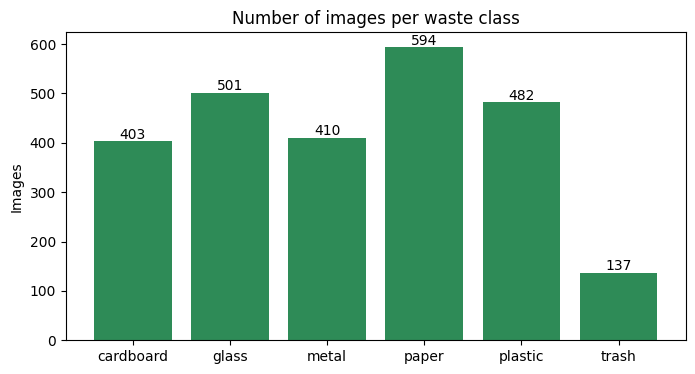

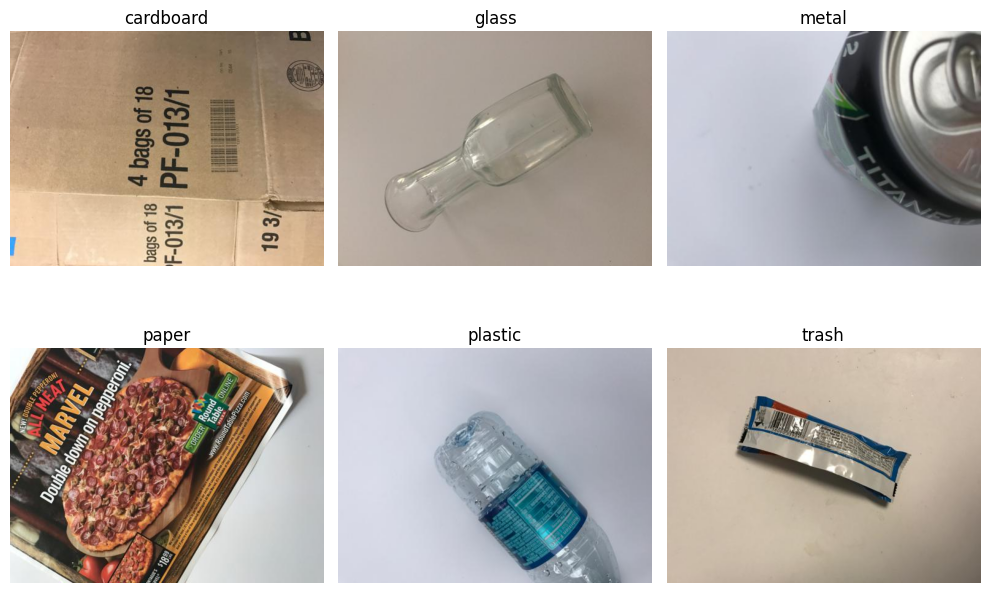

In [2]:
# Cell 2: visualizations - class balance + sample images
import matplotlib.pyplot as plt
from PIL import Image
import random

# --- Chart 1: how many images per class ---
counts = [len(os.listdir(os.path.join(DATA_DIR, c))) for c in classes]
plt.figure(figsize=(8, 4))
bars = plt.bar(classes, counts, color="seagreen")
plt.title("Number of images per waste class")
plt.ylabel("Images")
for bar, n in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, n + 5, str(n), ha="center")
plt.show()

# --- Chart 2: one random sample image from each class ---
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, c in zip(axes.flat, classes):
    folder = os.path.join(DATA_DIR, c)
    img_name = random.choice(os.listdir(folder))
    ax.imshow(Image.open(os.path.join(folder, img_name)))
    ax.set_title(c)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Data Processing: Train/Test Split

In [3]:
# Cell 3: split images into data/train (80%) and data/test (20%)
import shutil
from sklearn.model_selection import train_test_split

BASE_DIR = "/content/waste_project"
TRAIN_DIR = os.path.join(BASE_DIR, "data", "train")
TEST_DIR = os.path.join(BASE_DIR, "data", "test")

# Start clean in case you run this cell twice
if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)

for c in classes:
    folder = os.path.join(DATA_DIR, c)
    files = os.listdir(folder)

    # 80% train, 20% test, same random result every time (random_state=42)
    train_files, test_files = train_test_split(files, test_size=0.2, random_state=42)

    for split_dir, split_files in [(TRAIN_DIR, train_files), (TEST_DIR, test_files)]:
        os.makedirs(os.path.join(split_dir, c), exist_ok=True)
        for f in split_files:
            shutil.copy(os.path.join(folder, f), os.path.join(split_dir, c, f))

# Check the result
for name, d in [("TRAIN", TRAIN_DIR), ("TEST", TEST_DIR)]:
    print(name)
    total = 0
    for c in classes:
        n = len(os.listdir(os.path.join(d, c)))
        total += n
        print(f"  {c}: {n}")
    print(f"  total: {total}")

TRAIN
  cardboard: 322
  glass: 400
  metal: 328
  paper: 475
  plastic: 385
  trash: 109
  total: 2019
TEST
  cardboard: 81
  glass: 101
  metal: 82
  paper: 119
  plastic: 97
  trash: 28
  total: 508


## 4. Data Processing: Resizing, Validation Set, Class Weights

In [4]:
# Cell 4: load images, resize, create validation set, compute class weights
import tensorflow as tf
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Train (80% of the train folder) and validation (20% of the train folder)
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical")

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical")

# Test set: shuffle=False so predictions match labels when we evaluate
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False)

class_names = train_ds.class_names
print("Classes:", class_names)

# Speed up loading
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Class weights: smaller classes (like trash) get a bigger weight
labels = []
for i, c in enumerate(class_names):
    labels += [i] * len(os.listdir(os.path.join(TRAIN_DIR, c)))
weights = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=np.array(labels))
class_weights = dict(enumerate(weights))
print("Class weights:", {class_names[i]: round(w, 2) for i, w in class_weights.items()})

Found 2019 files belonging to 6 classes.
Using 1616 files for training.
Found 2019 files belonging to 6 classes.
Using 403 files for validation.
Found 508 files belonging to 6 classes.
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Class weights: {'cardboard': np.float64(1.05), 'glass': np.float64(0.84), 'metal': np.float64(1.03), 'paper': np.float64(0.71), 'plastic': np.float64(0.87), 'trash': np.float64(3.09)}


## 5. Model Creation (MobileNetV2 + augmentation, dropout, L2, early stopping)

In [5]:
# Cell 5: build the model (MobileNetV2) and train it
from tensorflow.keras import layers, models, regularizers, callbacks

NUM_CLASSES = len(class_names)

# Augmentation: random changes to training images so the model generalizes better
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

# Pretrained base (frozen = not changed during this training)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_model.trainable = False

# Put the pieces together
inputs = layers.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu",
                 kernel_regularizer=regularizers.l2(0.001))(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"])

# Early stopping: stop if validation loss does not improve for 4 epochs
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True)

# Train (class_weight fixes the "trash has fewer images" problem)
history = model.fit(
    train_ds, validation_data=val_ds, epochs=20,
    class_weight=class_weights, callbacks=[early_stop])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 17s 134ms/step - accuracy: 0.5105 - loss: 1.5754 - val_accuracy: 0.7122 - val_loss: 1.0368
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.6980 - loss: 1.0499 - val_accuracy: 0.7618 - val_loss: 0.9423
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.7426 - loss: 0.8918 - val_accuracy: 0.8387 - val_loss: 0.7609
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.7729 - loss: 0.8264 - val_accuracy: 0.8114 - val_loss: 0.7769
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.7877 - loss: 0.7808 - val_accuracy: 0.8462 - val_loss: 0.7304
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.8156 - loss: 0.6865 - val_accuracy: 0.8486 - val_loss: 0.7236
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.8342 - loss: 0.6844 - val_accuracy: 0.8313 - val_loss: 0.7231
Epoch 8/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accurac

## 6. Model Testing (accuracy, loss, precision, recall, F1, confusion matrix)

Test loss:     0.6363
Test accuracy: 0.8504

Classification report:
              precision    recall  f1-score   support

   cardboard      0.949     0.914     0.931        81
       glass      0.842     0.792     0.816       101
       metal      0.765     0.915     0.833        82
       paper      0.892     0.899     0.895       119
     plastic      0.900     0.742     0.814        97
       trash      0.649     0.857     0.738        28

    accuracy                          0.850       508
   macro avg      0.833     0.853     0.838       508
weighted avg      0.859     0.850     0.851       508



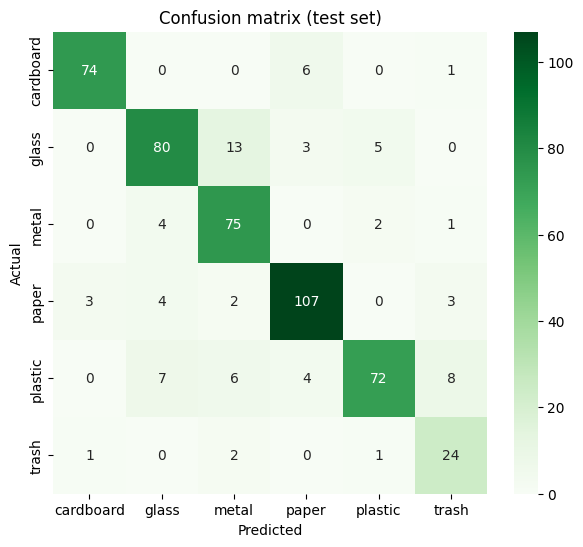

In [6]:
# Cell 6: evaluate on the test set - 5 metrics + confusion matrix
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

# Metric 1 and 2: test loss and test accuracy
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

# Get true labels and predicted labels
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)

# Metrics 3, 4, 5: precision, recall, F1 for each class
print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Confusion matrix chart
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (test set)")
plt.show()

## 7. Saving the Model

In [7]:
# Cell 7: save the model + class names, then download them
import json
from google.colab import files

MODELS_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

# Save the trained model (.h5 is allowed by the assignment)
model_path = os.path.join(MODELS_DIR, "waste_model.h5")
model.save(model_path)

# Save the class names (the API will need them later)
with open(os.path.join(MODELS_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

print("Saved files:", os.listdir(MODELS_DIR))

# Zip the models folder and download it to your computer
shutil.make_archive("/content/models_backup", "zip", MODELS_DIR)
files.download("/content/models_backup.zip")

Saved files: ['class_names.json', 'waste_model.h5']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Training Curves and Prediction Function

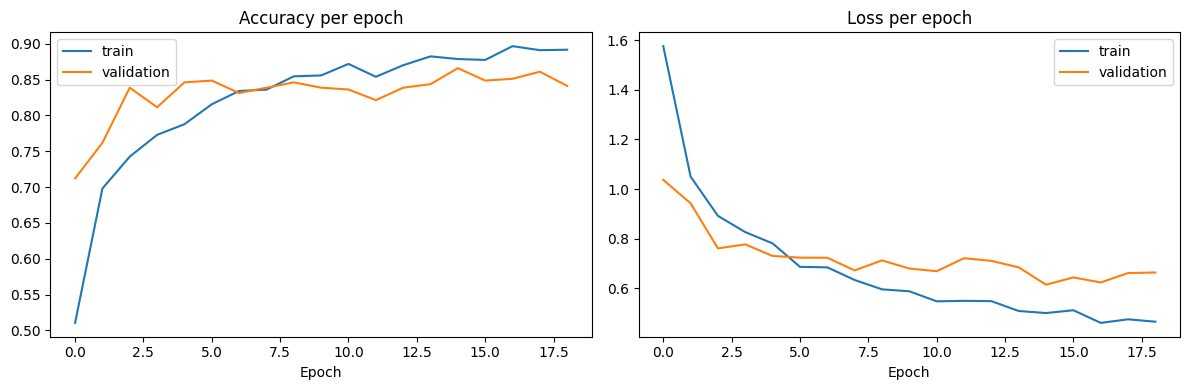

Actual: cardboard  | Predicted: cardboard  | Confidence: 99.26%
Actual: paper      | Predicted: paper      | Confidence: 99.43%
Actual: plastic    | Predicted: plastic    | Confidence: 91.40%


In [8]:
# Cell 8: training curves + prediction function
from tensorflow.keras.preprocessing import image as keras_image

# --- Part 1: training curves ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy per epoch")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss per epoch")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# --- Part 2: prediction function (one image in, class + confidence out) ---
def predict_image(img_path, model=model, class_names=class_names):
    img = keras_image.load_img(img_path, target_size=IMG_SIZE)
    arr = keras_image.img_to_array(img)
    arr = np.expand_dims(arr, axis=0)          # shape (1, 224, 224, 3)
    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    return class_names[idx], float(probs[idx])

# --- Part 3: try it on 3 random test images ---
for _ in range(3):
    c = random.choice(classes)
    f = random.choice(os.listdir(os.path.join(TEST_DIR, c)))
    path_img = os.path.join(TEST_DIR, c, f)
    pred, conf = predict_image(path_img)
    print(f"Actual: {c:10s} | Predicted: {pred:10s} | Confidence: {conf:.2%}")

## 9. Data Visualization: Brightness per Class

/tmp/ipykernel_629/2337033108.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(brightness.values(), labels=brightness.keys())


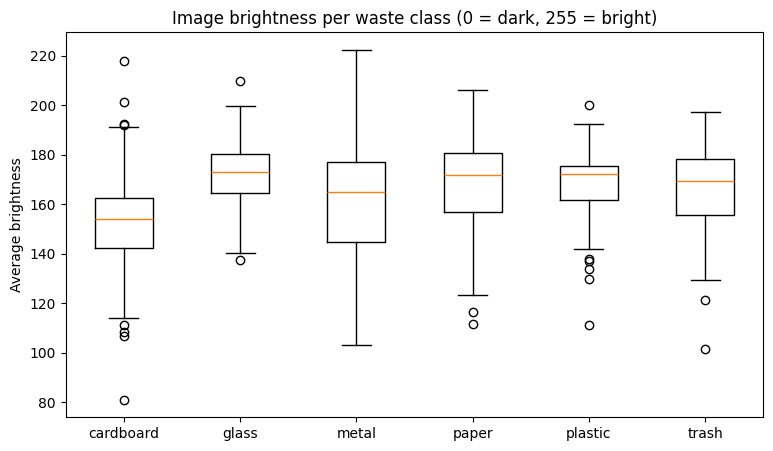

cardboard  average brightness: 152.9
glass      average brightness: 172.3
metal      average brightness: 161.3
paper      average brightness: 167.7
plastic    average brightness: 168.2
trash      average brightness: 166.8


In [9]:
# Cell 9: visualization 3 - average brightness per class
brightness = {}
for c in classes:
    folder = os.path.join(TRAIN_DIR, c)
    names = os.listdir(folder)[:100]      # up to 100 images per class (keeps it fast)
    values = []
    for n in names:
        img = Image.open(os.path.join(folder, n)).convert("L")   # "L" = grayscale
        values.append(np.array(img).mean())                       # 0 = black, 255 = white
    brightness[c] = values

plt.figure(figsize=(9, 5))
plt.boxplot(brightness.values(), labels=brightness.keys())
plt.title("Image brightness per waste class (0 = dark, 255 = bright)")
plt.ylabel("Average brightness")
plt.show()

# Print the average for each class so you can write your interpretation
for c, v in brightness.items():
    print(f"{c:10s} average brightness: {np.mean(v):.1f}")

## Data Visualization Interpretations

**1. Class balance (bar chart).** The dataset has 2,527 images across 6 classes, but it is imbalanced: paper has 594 images while trash has only 137. A model trained on this could learn to ignore trash. To fix this, I used class weights (trash gets a weight of 3.09), and I split each class folder 80/20 separately so every class keeps the same proportions in train and test. Trash still had the lowest F1 score (0.738), which confirms that fewer examples make a class harder to learn.

**2. Image variety (sample grid).** Photos of the same class differ in angle, lighting, and object type (for example, plastic bottles and plastic bags). So the model must learn shapes and textures, not memorize pictures. This is why I added data augmentation (flips, rotation, zoom) and used a pretrained model.

**3. Brightness per class (box plot).** Cardboard is the darkest class (average 152.9), likely because of its brown color, and glass is the brightest (172.3), likely because of reflections. The other classes are close together (161 to 168). The gap is small, so brightness alone cannot separate the classes. The model must rely on shape and texture, which supports the choice of a deep learning model over simple pixel statistics.